# Часть 1. Проверка гипотезы в Python и составление аналитической записки

## Итоговый проект 3 модуля: Яндекс Книги

- Автор: Тоскина У.А.
- Дата: 16.05.2026

## Цели и задачи проекта

Цель проекта - проанализировать активность пользователей в сервисе Яндекс Книги и проверить гипотезу о том, что пользователи из Санкт-Петербурга проводят в приложении больше времени, чем пользователи из Москвы.

Для достижения цели были поставлены следующие задачи:
- загрузить и изучить данные
- провести предобработку данных, проверить на наличие пропусков и дубликатов
- сформировать независимые группы пользователей
- исследовать распределение активности пользователей
- выбрать подходящий статистический тест и проверить гипотезу
- интерпретировать результаты статистического теста

## Описание данных

В проекте используются данные пользователей из Москвы и Санкт-Петербурга c их активностью (суммой часов чтения и прослушивания) из файла /.csv

## Содержимое проекта

1. Загрузка данных и знакомство с ними
2. Проверка гипотезы в Python
3. Аналитическая записка

## 1. Загрузка данных и знакомство с ними

Загрузите данные пользователей из Москвы и Санкт-Петербурга c их активностью (суммой часов чтения и прослушивания) из файла ``.

In [ ]:
import pandas as pd
from scipy.stats import mannwhitneyu

from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

from statsmodels.stats.proportion import proportions_ztest

In [ ]:
yandex_knigi_data = pd.read_csv('')
yandex_knigi_data.head()

,Unnamed: 0,city,puid,hours
0,0,Москва,9668,26.167776
1,1,Москва,16598,82.111217
2,2,Москва,80401,4.656906
3,3,Москва,140205,1.840556
4,4,Москва,248755,151.326434


In [ ]:
yandex_knigi_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8784 entries, 0 to 8783
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  8784 non-null   int64  
 1   city        8784 non-null   object 
 2   puid        8784 non-null   int64  
 3   hours       8784 non-null   float64
dtypes: float64(1), int64(2), object(1)
memory usage: 274.6+ KB


В данных 8784 строки, в которых нет пропусков.

Удалим лишний столбец Unnamed: 0. Проверим данные на наличие дубликатов в идентификаторах пользователей.

In [ ]:
yandex_knigi_data = yandex_knigi_data.drop(columns = 'Unnamed: 0')
yandex_knigi_data.head()

,city,puid,hours
0,Москва,9668,26.167776
1,Москва,16598,82.111217
2,Москва,80401,4.656906
3,Москва,140205,1.840556
4,Москва,248755,151.326434


In [ ]:
yandex_knigi_data.duplicated().sum()

0

In [ ]:
yandex_knigi_data['puid'].duplicated().sum()

244

Полных дубликатов в данных не обнаружено, а вот в идентификаторах пользователей есть 244 дубликата. Рассмотрим их.

In [ ]:
yandex_knigi_data[yandex_knigi_data['puid'].duplicated(keep = False)].sort_values('puid')

,city,puid,hours
35,Москва,2637041,10.317371
6247,Санкт-Петербург,2637041,3.883926
134,Москва,9979490,32.415573
6274,Санкт-Петербург,9979490,1.302997
145,Москва,10597984,42.931506
...,...,...,...
6195,Москва,1130000020425037,0.310556
8775,Санкт-Петербург,1130000023864516,14.384722
6202,Москва,1130000023864516,142.830085
6210,Москва,1130000028554332,11.277554


Можно заметить, что дубликаты по идентификаторам пользователей связаны с тем, что некоторые пользователи встречаются в разных городах. Проверим, есть ли дубликаты по сочетанию города и идентификатора.

In [ ]:
yandex_knigi_data[['puid', 'city']].duplicated().sum()

0

Дубликатов по сочетанию города и идентификатора нет. Таким образом, в данных повторяются только пользователи, которые имеют сессии в обоих городах. Далее мы будем проводить тест на группах из разных городов, поэтому наличие пользователей из обоих городов сделает группы зависимыми. Удалим таких пользователей из датафрейма.

In [ ]:
duplicated_users = yandex_knigi_data[yandex_knigi_data['puid'].duplicated(keep = False)]['puid'].unique()
yandex_knigi_data = yandex_knigi_data[~ yandex_knigi_data['puid'].isin(duplicated_users)]
yandex_knigi_data.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 8296 entries, 0 to 8783
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   city    8296 non-null   object 
 1   puid    8296 non-null   int64  
 2   hours   8296 non-null   float64
dtypes: float64(1), int64(1), object(1)
memory usage: 259.2+ KB


Было удалено 488 строк (244 дубликата) с данными о пользователях в обоих городах, теперь группы для теста можно считать независимыми.

Сформируем 2 группы и сравним их размеры и статистики.

In [ ]:
msc = yandex_knigi_data[yandex_knigi_data['city'] == 'Москва']
spb = yandex_knigi_data[yandex_knigi_data['city'] == 'Санкт-Петербург']
msc.shape[0], spb.shape[0]

(5990, 2306)

Группа пользователей из Москвы более, чем в 2,5 раза больше группы Санкт-Петербурга. Посмотрим их статистики.

(count    5990.000000
 mean       10.848192
 std        36.925622
 min         0.000022
 25%         0.057042
 50%         0.888232
 75%         5.933439
 max       857.209373
 Name: hours, dtype: float64,
 <AxesSubplot:>)

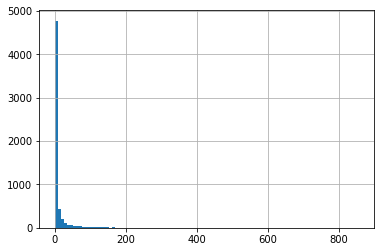

In [ ]:
msc['hours'].describe(), msc['hours'].hist(bins = 100)

(count    2306.000000
 mean       11.264433
 std        39.831755
 min         0.000025
 25%         0.060173
 50%         0.875355
 75%         6.138424
 max       978.764775
 Name: hours, dtype: float64,
 <AxesSubplot:>)

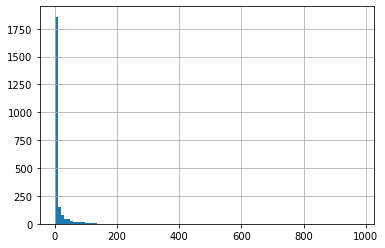

In [ ]:
spb['hours'].describe(), spb['hours'].hist(bins = 100)

Распределение часовой активности пользователей в обеих группах скошено вправо: большая часть пользователей имеют относительно короткие сессии, но встречается небольшое количество пользователей с очень высокой активностью.

Максимальные значения значительно превышают медианные. Но форма распределений в городах выглядит схожей.

Несмотря на наличие выбросов, удалять их не будем: часть из экстремально больших значений, вероятно, является выбросами, но без дополнительной информации сложно определить корректный порог отсечения. Произвольная граница может исказить результаты больше, чем наличие выбросов.
Для проверки гипотезы необходимо будет использовать статистический тест, устойчивый к такому распределению и выбросам.

## 2. Проверка гипотезы в Python

Гипотеза звучит так: пользователи из Санкт-Петербурга проводят в среднем больше времени за чтением и прослушиванием книг в приложении, чем пользователи из Москвы. Попробуем статистически это доказать, используя одностороннюю проверку гипотезы с двумя выборками:

- Нулевая гипотеза H₀: Средняя активность пользователей в часах в двух группах (Москва и Санкт-Петербург) не различается.

- Альтернативная гипотеза H₁: Средняя активность пользователей в Санкт-Петербурге больше, и это различие статистически значимо.

Проведем тест Манна-Уитни, так как он нечувствителен к выбросам - не требует нормального распределения.

In [ ]:
alpha = 0.05
mw_test = mannwhitneyu(msc['hours'],
                      spb['hours'],
                      alternative = 'less')

if mw_test.pvalue > alpha:
    print(f'pvalue = {round(mw_test.pvalue, 2)} > {alpha}')
    print('Нулевая гипотеза не отвергается! Распределение метрики в группах A и B равны')
else:
    print(f'pvalue = {round(mw_test.pvalue, 2)} < {alpha}')
    print('Нулевая гипотеза не находит подтверждение! Распределение метрики в группе B больше A')

pvalue = 0.45 > 0.05
Нулевая гипотеза не отвергается! Распределение метрики в группах A и B равны


По результатам теста нет статистических оснований считать, что пользователи из Санкт-Петербурга проводят больше времени в приложении, чем пользователи из Москвы.

## 3. Аналитическая записка




Для проверки гипотезы был использован односторонний тест Манна-Уитни со стандартным уровнем статистической значимости 5%. Этот тест был выбран из-за того, что распределение активности пользователей оказалось слишком скошенным и содержало выбросы.

По итогам теста было получено p-value = 0,45.
Так как p-value превышает уровень значимости, не получилось отвергнуть нулевую гипотезу. Статистически значимых оснований, что пользователи из Санкт-Петербурга проводят в сервисе больше времени, чем пользователи из Москвы, не обнаружено.

Причиной такого результата может быть схожий характер поведения пользователей сервиса в двух крупнейших городах России. Кроме того, несмотря на небольшое различие средних значений активности пользователей, разброс данных внутри групп оказался слишком большим.

----

# Часть 2. Анализ результатов A/B-тестирования

## 1. Цели исследования.



Цели исследования - оценить корректность проведения А/В-теста и проанализировать результаты эксперимента по изменению интерфейса интернет-магазина BitMotion Kit.

В рамках исследования необходимо:
- загрузить и изучить данные теста
- проверить целостность и корректность данных
- проверить распределение пользователей по группам
- оценить изменение конверсии пользователей в покупателей
- проверить статистическую значимость различий между группами
- сделать вывод об эффективности нового интерфейса

## 2. Загрузка данных и оценка их целостности.


In [ ]:
participants = pd.read_csv('')
events = pd.read_csv('',
                     parse_dates=['event_dt'], low_memory=False)

In [ ]:
participants.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14525 entries, 0 to 14524
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   user_id  14525 non-null  object
 1   group    14525 non-null  object
 2   ab_test  14525 non-null  object
 3   device   14525 non-null  object
dtypes: object(4)
memory usage: 454.0+ KB


In [ ]:
participants.head()

,user_id,group,ab_test,device
0,0002CE61FF2C4011,B,interface_eu_test,Mac
1,001064FEAAB631A1,B,recommender_system_test,Android
2,001064FEAAB631A1,A,interface_eu_test,Android
3,0010A1C096941592,A,recommender_system_test,Android
4,001E72F50D1C48FA,A,interface_eu_test,Mac


In [ ]:
events.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 787286 entries, 0 to 787285
Data columns (total 4 columns):
 #   Column      Non-Null Count   Dtype         
---  ------      --------------   -----         
 0   user_id     787286 non-null  object        
 1   event_dt    787286 non-null  datetime64[ns]
 2   event_name  787286 non-null  object        
 3   details     249022 non-null  object        
dtypes: datetime64[ns](1), object(3)
memory usage: 24.0+ MB


In [ ]:
events.head()

,user_id,event_dt,event_name,details
0,GLOBAL,2020-12-01 00:00:00,End of Black Friday Ads Campaign,ZONE_CODE15
1,CCBE9E7E99F94A08,2020-12-01 00:00:11,registration,0.0
2,GLOBAL,2020-12-01 00:00:25,product_page,NaN
3,CCBE9E7E99F94A08,2020-12-01 00:00:33,login,NaN
4,CCBE9E7E99F94A08,2020-12-01 00:00:52,product_page,NaN


В обоих датафреймах данные представлены корректно. Пропусков в данных нет, за исключением столбца `details`, в котором указана дополнительная информация. Проверим на наличие дубликатов.

In [ ]:
participants.duplicated().sum(), events.duplicated().sum()

(0, 36318)

В таблице с информацией о распределении пользователей по группам тестов дубликатов нет, а вот в таблице `events` с информацией о действиях пользователей найдено 36 318 полных дубликатов, удалим их.

In [ ]:
events = events.drop_duplicates()

In [ ]:
events.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 750968 entries, 0 to 787285
Data columns (total 4 columns):
 #   Column      Non-Null Count   Dtype         
---  ------      --------------   -----         
 0   user_id     750968 non-null  object        
 1   event_dt    750968 non-null  datetime64[ns]
 2   event_name  750968 non-null  object        
 3   details     244905 non-null  object        
dtypes: datetime64[ns](1), object(3)
memory usage: 28.6+ MB


После удаления дубликатов датафрейм `events` содержит 750 968 строк. Данные готовы к дальнейшей проверке корректности проведения A/B-теста.

## 3. По таблице `ab_test_participants` оценим корректность проведения теста:

   3\.1 Выделим пользователей, участвующих в тесте, и проверим:

   - соответствие требованиям технического задания,

   - равномерность распределения пользователей по группам теста,

   - отсутствие пересечений с конкурирующим тестом (нет пользователей, участвующих одновременно в двух тестовых группах).

In [ ]:
interface_test = participants[participants['ab_test'] == 'interface_eu_test']
interface_test.head()

,user_id,group,ab_test,device
0,0002CE61FF2C4011,B,interface_eu_test,Mac
2,001064FEAAB631A1,A,interface_eu_test,Android
4,001E72F50D1C48FA,A,interface_eu_test,Mac
5,002412F1EB3F6E38,B,interface_eu_test,Mac
6,002540BE89C930FB,B,interface_eu_test,Android


In [ ]:
interface_test['group'].value_counts()

B    5467
A    5383
Name: group, dtype: int64

In [ ]:
interface_test['group'].value_counts(normalize = True)

B    0.503871
A    0.496129
Name: group, dtype: float64

In [ ]:
users_interface_test = set(participants[participants['ab_test'] == 'interface_eu_test']['user_id'])
users_recommender_system_test = set(participants[participants['ab_test'] == 'recommender_system_test']['user_id'])
intersection = users_interface_test & users_recommender_system_test
len(intersection)

887

In [ ]:
participants[participants['user_id'].isin(intersection)].pivot_table(index = 'user_id', columns='ab_test',
    values='group',
    aggfunc='first'
).head()

ab_test,interface_eu_test,recommender_system_test
user_id,,
001064FEAAB631A1,A,B
00341D8401F0F665,B,A
0082295A41A867B5,A,A
00E68F103C66C1F7,A,A
00EFA157F7B6E1C4,B,A


887 пользователей участвуют одновременно в двух экспериментах. При этом часть пользователей находится в разных группах тестов одновременно. Такое пересечение может исказить результаты теста, удалим таких пользователей.

In [ ]:
interface_test = interface_test[~interface_test['user_id'].isin(intersection)]
interface_test['group'].value_counts()

B    5011
A    4952
Name: group, dtype: int64

In [ ]:
interface_test.groupby('user_id')['group'].nunique().value_counts()

1    9963
Name: group, dtype: int64

Пользователи, участвующие в обоих экспериментах, были удалены. Пользователи, которые попали одновременно в обе группы внутри одного теста, не обнаружены.

3\.2 Проанализируем данные о пользовательской активности по таблице `ab_test_events`:

- оставим только события, связанные с участвующими в изучаемом тесте пользователями;

In [ ]:
events_test = events[events['user_id'].isin(interface_test['user_id'])]
events_test.head()

,user_id,event_dt,event_name,details
64672,5F506CEBEDC05D30,2020-12-06 14:10:01,registration,0.0
64946,51278A006E918D97,2020-12-06 14:37:25,registration,-3.8
66585,A0C1E8EFAD874D8B,2020-12-06 17:20:22,registration,-3.32
67873,275A8D6254ACF530,2020-12-06 19:36:54,registration,-0.48
67930,0B704EB2DC7FCA4B,2020-12-06 19:42:20,registration,0.0


- определим горизонт анализа: рассчитаем время (лайфтайм) совершения события пользователем после регистрации и оставим только те события, которые были выполнены в течение первых семи дней с момента регистрации;

Определим дату регистрации, рассчитаем лайфтайм событий и оставим только события, произошедшие в первые 7 дней после регистрации.

In [ ]:
registration_date = events_test[events_test['event_name'] == 'registration'][['user_id', 'event_dt']].rename(columns = {'event_dt': 'registration_dt'})
registration_date.head()

,user_id,registration_dt
64672,5F506CEBEDC05D30,2020-12-06 14:10:01
64946,51278A006E918D97,2020-12-06 14:37:25
66585,A0C1E8EFAD874D8B,2020-12-06 17:20:22
67873,275A8D6254ACF530,2020-12-06 19:36:54
67930,0B704EB2DC7FCA4B,2020-12-06 19:42:20


In [ ]:
events_test = events_test.merge(registration_date, on = 'user_id', how = 'left')
events_test.head()

,user_id,event_dt,event_name,details,registration_dt
0,5F506CEBEDC05D30,2020-12-06 14:10:01,registration,0.0,2020-12-06 14:10:01
1,51278A006E918D97,2020-12-06 14:37:25,registration,-3.8,2020-12-06 14:37:25
2,A0C1E8EFAD874D8B,2020-12-06 17:20:22,registration,-3.32,2020-12-06 17:20:22
3,275A8D6254ACF530,2020-12-06 19:36:54,registration,-0.48,2020-12-06 19:36:54
4,0B704EB2DC7FCA4B,2020-12-06 19:42:20,registration,0.0,2020-12-06 19:42:20


In [ ]:
events_test['lifetime'] = (events_test['event_dt'] - events_test['registration_dt']).dt.days

In [ ]:
events_test = events_test[events_test['lifetime'] < 7]
events_test.head()

,user_id,event_dt,event_name,details,registration_dt,lifetime
0,5F506CEBEDC05D30,2020-12-06 14:10:01,registration,0.0,2020-12-06 14:10:01,0
1,51278A006E918D97,2020-12-06 14:37:25,registration,-3.8,2020-12-06 14:37:25,0
2,A0C1E8EFAD874D8B,2020-12-06 17:20:22,registration,-3.32,2020-12-06 17:20:22,0
3,275A8D6254ACF530,2020-12-06 19:36:54,registration,-0.48,2020-12-06 19:36:54,0
4,0B704EB2DC7FCA4B,2020-12-06 19:42:20,registration,0.0,2020-12-06 19:42:20,0


После расчета лайфтайма были оставлены только события, произошедшие в течение 7 дней после регистрации.

Оценим достаточность выборки для получения статистически значимых результатов A/B-теста. Заданные параметры:

- базовый показатель конверсии — 30%,

- мощность теста — 80%,

- достоверность теста — 95%.

In [ ]:
alpha = 0.05
beta = 0.2
power = 1 - beta
p = 0.3
mde = 0.03

effect_size = proportion_effectsize(p, p + mde)
power_analysis = NormalIndPower()

sample_size = power_analysis.solve_power(
    effect_size = effect_size,
    power = power,
    alpha = alpha,
    ratio = 1
)

print(f"Необходимый размер выборки для каждой группы: {int(sample_size)}")


Необходимый размер выборки для каждой группы: 3761


Необходимо не менее 3761 пользователя в каждой группе. После очистки данных в тесте осталось 4952 пользователя в группе А и 5011 в группе В - размеры обеих групп превышают минимальные требования, поэтому выборку можно считать достаточной для проведения теста.

- рассчитаем для каждой группы количество посетителей, сделавших покупку, и общее количество посетителей.

In [ ]:
events_test = events_test.merge(interface_test[['user_id', 'group']], on = 'user_id', how = 'left')
events_test.head()

,user_id,event_dt,event_name,details,registration_dt,lifetime,group
0,5F506CEBEDC05D30,2020-12-06 14:10:01,registration,0.0,2020-12-06 14:10:01,0,A
1,51278A006E918D97,2020-12-06 14:37:25,registration,-3.8,2020-12-06 14:37:25,0,A
2,A0C1E8EFAD874D8B,2020-12-06 17:20:22,registration,-3.32,2020-12-06 17:20:22,0,B
3,275A8D6254ACF530,2020-12-06 19:36:54,registration,-0.48,2020-12-06 19:36:54,0,A
4,0B704EB2DC7FCA4B,2020-12-06 19:42:20,registration,0.0,2020-12-06 19:42:20,0,B


In [ ]:
total_users = interface_test.groupby('group')['user_id'].nunique()
buyers = events_test[events_test['event_name'] == 'purchase'].groupby('group')['user_id'].nunique()
total_users, buyers

(group
 A    4952
 B    5011
 Name: user_id, dtype: int64,
 group
 A    1377
 B    1480
 Name: user_id, dtype: int64)

In [ ]:
buyers / total_users

group
A    0.278069
B    0.295350
Name: user_id, dtype: float64

Конверсия в покупку в тестовой группе В (29,5%) немного выше, чем в контрольной грппе А (27,8%). Однако на данном этапе нельзя сделать вывод о статистической значимости различий. Необходимо провести статистический тест.

## 4. Проведите оценку результатов A/B-тестирования:

Проверим, отличается ли конверсия в покупку между группами статистически.
Нулевая гипотеза Н0: Конверсия в покупку в группах А и В не различается
Альтернативная гипотеза Н1: Конверсия в покупку в группе В больше, чем в группе А.

In [ ]:
n_a = total_users['A']
n_b = total_users['B']

m_a = buyers['A']
m_b = buyers['B']

p_a = m_a / n_a
p_b = m_b / n_b

if (p_a*n_a > 10)&((1-p_a)*n_a > 10)&(p_b*n_b>10)&((1-p_b)*n_b>10):
    print('Предпосылка о достаточном количестве данных выполняется')
else:
    print('Предпосылка о достаточном количестве данных не выполняется')

Предпосылка о достаточном количестве данных выполняется


In [ ]:
alpha = 0.05

stat_ztest, p_value_ztest = proportions_ztest([m_a, m_b],
                                             [n_a, n_b],
                                             alternative = 'smaller')
print(f'p-value = {round(p_value_ztest, 2)}')

if p_value_ztest > alpha:
    print('Нулевая гипотеза находит подтверждение')
else:
    print('Нулевая гипотеза не находит подтверждение')

p-value = 0.03
Нулевая гипотеза не находит подтверждение


Для проверки различий конверсии между группами был использован односторонний z-тест пропорций с уровнем статистической значимости 5%.

В результате теста получено p-value = 0.03, что меньше уровня статистической значимости - нулевая гипотеза не нашла подтверждения. Значит, различие между группами статистически значимо: конверсия в группе В выше, чем в группе А.

Однако ожидаемый эффект эксперимента не достигнут:  согласно ТЗ, тест должен был показать рост конверсии минимум на 3 процентных пункта, а фактический прирост оказался ниже (~1,7).

Новый интерфейс действительно положительно повлиял на конверсию посетителей в покупку, однако эффект оказался слабее ожидаемого.

Рекомендации для улучшения данной метрики:
        
- Провести дополнительный анализ по сегментам — возможно, новый интерфейс работает лучше для отдельных групп (мобильные пользователи, новички и т.д.);
- Запустить дополнительные A/B-тесты с другими UX-гипотезами: добавление подсказок, этапов онбординга, изменения CTA;
- Изучить поведение пользователей воронки после регистрации — где именно теряется интерес;
- Собрать качественную обратную связь от пользователей — чтобы понять, какие барьеры мешают сделать покупку;
- Сфокусироваться на других точках роста, например, на продлении LTV, повышении Retention или улучшении маркетингового взаимодействия.